# UTS Graf Sains Data — Wrangling, EDA, VSM, Similarity, KNN

**Periode aktual pada data yang tersedia:** 
- P1/training = 2015-05-15 s.d. 2015-05-28
- P2/testing = 2015-05-29 s.d. 2015-06-04 (UTC). 

## 0. Instalasi dan konfigurasi

In [1]:
%pip install -q pandas numpy matplotlib seaborn scipy scikit-learn networkx neo4j tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import os
import zipfile
import shutil
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors
try:
    from neo4j import GraphDatabase
except ImportError:
    GraphDatabase = None

SEED = 42
rng = np.random.default_rng(SEED)

ZIP_PATH = Path("data.zip")
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

if not ZIP_PATH.exists():
    candidates = list(Path.cwd().glob("*.zip"))
    if candidates:
        ZIP_PATH = candidates[0]

if ZIP_PATH.exists():
    with zipfile.ZipFile(ZIP_PATH) as z:
        names = set(z.namelist())
        for member in ["data/events_p1.csv", "data/events_p2.csv"]:
            if member not in names:
                raise FileNotFoundError(f"{member} tidak ditemukan di {ZIP_PATH}")
            target = Path(member)
            target.parent.mkdir(parents=True, exist_ok=True)
            with z.open(member) as src, open(target, "wb") as dst:
                shutil.copyfileobj(src, dst)

P1_PATH = DATA_DIR / "events_p1.csv"
P2_PATH = DATA_DIR / "events_p2.csv"
if not P1_PATH.exists() or not P2_PATH.exists():
    raise FileNotFoundError("events_p1.csv dan events_p2.csv tidak ditemukan. Letakkan data.zip di folder notebook.")

URI = os.getenv("NEO4J_URI", "bolt://127.0.0.1:7687")
USER = os.getenv("NEO4J_USER", "neo4j")
PASSWORD = os.getenv("NEO4J_PASSWORD", "GSD12345")
DATABASE = os.getenv("NEO4J_DATABASE", "neo4j")

BATCH_SIZE = 10_000
IMPORT_TO_NEO4J = False  # Ubah True jika Neo4j lokal sudah aktif dan password benar.

print("=" * 60)
print("KONFIGURASI UTS GRAF SAINS DATA — SESUAI DATA UPLOAD")
print("=" * 60)
print("ZIP            :", ZIP_PATH)
print("P1 dataset     :", P1_PATH)
print("P2 dataset     :", P2_PATH)
print("Neo4j URI      :", URI)
print("Neo4j User     :", USER)
print("Neo4j Database :", DATABASE)
print("Random seed    :", SEED)
print("Batch size     :", BATCH_SIZE)
print("Import Neo4j   :", IMPORT_TO_NEO4J)
print("=" * 60)


KONFIGURASI UTS GRAF SAINS DATA — SESUAI DATA UPLOAD
ZIP            : data.zip
P1 dataset     : data\events_p1.csv
P2 dataset     : data\events_p2.csv
Neo4j URI      : bolt://127.0.0.1:7687
Neo4j User     : neo4j
Neo4j Database : neo4j
Random seed    : 42
Batch size     : 10000
Import Neo4j   : False


## 2.1.1–2 — Wrangling: baca data P1/P2 dari ZIP

`timestamp` pada data RetailRocket adalah epoch **milidetik**. Data upload sudah menyediakan `events_p1.csv` dan `events_p2.csv`, sehingga tidak perlu membuat filter tanggal baru dari `events.csv` yang merupakan pointer Git LFS. Rentang waktu di bawah diverifikasi langsung dari kedua file tersebut.


In [3]:
def load_period_csv(path, period_name):
    df = pd.read_csv(path)
    required = {"timestamp", "visitorid", "event", "itemid", "transactionid"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Kolom wajib hilang pada {path}: {missing}")
    df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True, errors="coerce")
    df["visitorid"] = pd.to_numeric(df["visitorid"], errors="coerce")
    df["itemid"] = pd.to_numeric(df["itemid"], errors="coerce")
    df = df.dropna(subset=["datetime", "visitorid", "itemid", "event"]).copy()
    df["visitorid"] = df["visitorid"].astype("int64")
    df["itemid"] = df["itemid"].astype("int64")
    df["period"] = period_name
    return df

p1 = load_period_csv(P1_PATH, "P1")
p2 = load_period_csv(P2_PATH, "P2")

p1.to_csv("events_P1_training.csv", index=False)
p2.to_csv("events_P2_testing.csv", index=False)

print("P1 events:", len(p1), "| P2 events:", len(p2))
print("P1 range:", p1.datetime.min(), "hingga", p1.datetime.max())
print("P2 range:", p2.datetime.min(), "hingga", p2.datetime.max())
print("P1 disimpan: events_P1_training.csv | P2 disimpan: events_P2_testing.csv")


P1 events: 304718 | P2 events: 145321
P1 range: 2015-05-15 00:00:01.871000+00:00 hingga 2015-05-28 23:59:58.485000+00:00
P2 range: 2015-05-29 00:00:00.738000+00:00 hingga 2015-06-04 23:59:56.235000+00:00
P1 disimpan: events_P1_training.csv | P2 disimpan: events_P2_testing.csv


Komposisi event P1:


,jumlah
event,
view,295268
addtocart,7111
transaction,2339


Komposisi event P2:


,jumlah
event,
view,140674
addtocart,3480
transaction,1167


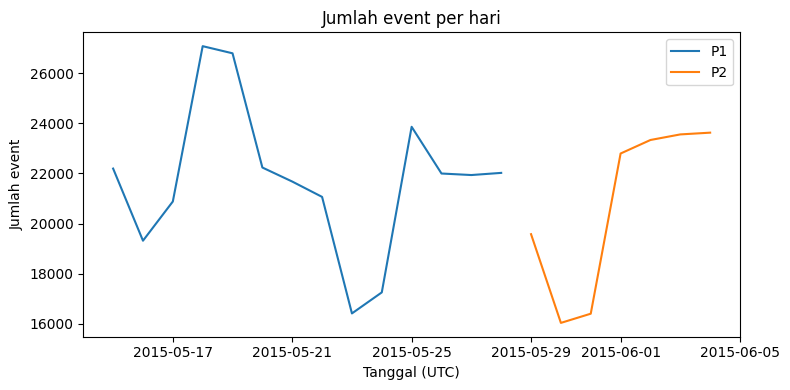

In [4]:
print("Komposisi event P1:")
display(p1.event.value_counts().rename_axis("event").to_frame("jumlah"))
print("Komposisi event P2:")
display(p2.event.value_counts().rename_axis("event").to_frame("jumlah"))
fig, ax = plt.subplots(figsize=(8,4))
p1.assign(day=p1.datetime.dt.date).groupby("day").size().plot(ax=ax, label="P1")
p2.assign(day=p2.datetime.dt.date).groupby("day").size().plot(ax=ax, label="P2")
ax.set_title("Jumlah event per hari"); ax.set_xlabel("Tanggal (UTC)"); ax.set_ylabel("Jumlah event"); ax.legend(); plt.tight_layout(); plt.show()

## 2.1.3 — Impor subgraph periode P1 ke Neo4j dan komposisi node

Impor P1 saja agar graf yang dieksplorasi merepresentasikan data training. Query menggunakan `MERGE` untuk node dan `CREATE` untuk tiap event relationship. `IMPORT_TO_NEO4J` default `False` supaya notebook tetap dapat dijalankan tanpa server Neo4j; aktifkan setelah Neo4j lokal siap.


In [5]:
def import_batch(tx, batch):
    q = """
    UNWIND $batch AS row
    MERGE (u:User {userId: toInteger(row.visitorid)})
    MERGE (i:Item {itemId: toInteger(row.itemid)})
    WITH u, i, row
    CALL {
      WITH u, i, row WHERE row.event='view'
      CREATE (u)-[:VIEWED {timestamp: toInteger(row.timestamp)}]->(i) RETURN count(*) AS n
      UNION ALL
      WITH u, i, row WHERE row.event='addtocart'
      CREATE (u)-[:ADDED_TO_CART {timestamp: toInteger(row.timestamp)}]->(i) RETURN count(*) AS n
      UNION ALL
      WITH u, i, row WHERE row.event='transaction'
      CREATE (u)-[:BOUGHT {timestamp: toInteger(row.timestamp), transactionId: row.transactionid}]->(i) RETURN count(*) AS n
    }
    RETURN count(*) AS processed
    """
    tx.run(q, batch=batch).consume()

if IMPORT_TO_NEO4J:
    with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
        driver.verify_connectivity()
        with driver.session(database=DATABASE) as session:
            session.run("CREATE CONSTRAINT user_id IF NOT EXISTS FOR (u:User) REQUIRE u.userId IS UNIQUE").consume()
            session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE").consume()
            for start in range(0, len(p1), BATCH_SIZE):
                batch = p1.iloc[start:start+BATCH_SIZE].copy()
                batch["transactionid"] = batch["transactionid"].where(batch["transactionid"].notna(), None)
                records = batch[["visitorid", "itemid", "event", "timestamp", "transactionid"]].to_dict("records")
                session.execute_write(import_batch, records)
    print("Impor P1 ke Neo4j selesai")
else:
    print("Impor Neo4j dilewati. Analisis Python tetap dapat dijalankan.")


Impor Neo4j dilewati. Analisis Python tetap dapat dijalankan.


### Query Cypher untuk komposisi graf

Label node: `User`, `Item`. Relationship: `VIEWED`, `ADDED_TO_CART`, `BOUGHT`. Query berikut dijalankan melalui Python API dan mencetak jumlah masing-masing tipe.

In [6]:
if IMPORT_TO_NEO4J:
    with GraphDatabase.driver(URI,auth=(USER,PASSWORD)) as driver:
        with driver.session(database=DATABASE) as session:
            node_q = "MATCH (n) WHERE n:User OR n:Item RETURN labels(n) AS label, count(*) AS jumlah ORDER BY label"
            rel_q = "MATCH ()-[r]->() WHERE type(r) IN ['VIEWED','ADDED_TO_CART','BOUGHT'] RETURN type(r) AS tipe, count(*) AS jumlah ORDER BY tipe"
            print("Node:")
            for row in session.run(node_q): print(row["label"], row["jumlah"])
            print("Relationship:")
            for row in session.run(rel_q): print(row["tipe"], row["jumlah"])
else: print("Impor Neo4j dilewati")

Impor Neo4j dilewati


**Penjelasan Cypher:** `MATCH` mencocokkan pola node/relationship; `labels(n)` mengembalikan label node; `type(r)` mengambil tipe relationship; `count(*)` menghitung record hasil; `ORDER BY` mengurutkan hasil. Gunakan `RETURN` untuk menampilkan hasil query.

## 2.1.4–6 — VSM, proyeksi User dan Item, dan visualisasi graf

Bentuk matriks interaksi user-item dari P1. Notebook kemudian menghitung cosine similarity untuk proyeksi User-User dan Item-Item. Visualisasi menampilkan node dan edge nyata dari matriks similarity; jumlah node/edge dibatasi untuk keterbacaan, sedangkan perbandingan ukuran ditampilkan pada grafik batang.


In [7]:
# Gunakan semua jenis event sebagai sinyal interaksi; bisa diganti dengan transaksi saja untuk analisis alternatif.
MIN_USER_EVENTS = 3
MIN_ITEM_EVENTS = 3
MAX_USERS = 1500
MAX_ITEMS = 2500
inter = p1[["visitorid","itemid","event"]].copy()
user_counts = inter.visitorid.value_counts()
item_counts = inter.itemid.value_counts()
valid_users = user_counts[user_counts >= MIN_USER_EVENTS].head(MAX_USERS).index
valid_items = item_counts[item_counts >= MIN_ITEM_EVENTS].head(MAX_ITEMS).index
inter = inter[inter.visitorid.isin(valid_users) & inter.itemid.isin(valid_items)].copy()
# Matriks frekuensi; setiap event dihitung sebagai satu interaksi.
agg = inter.groupby(["visitorid","itemid"]).size().reset_index(name="weight")
users = pd.Index(sorted(agg.visitorid.unique()), name="visitorid")
items = pd.Index(sorted(agg.itemid.unique()), name="itemid")
ui = csr_matrix((agg.weight.astype(float),(users.get_indexer(agg.visitorid),items.get_indexer(agg.itemid))),shape=(len(users),len(items)))
print("Jumlah event setelah pembatasan:",len(inter))
print("VSM User x Item shape:",ui.shape,"| nonzero:",ui.nnz,"| density:",ui.nnz/(ui.shape[0]*ui.shape[1]))
print("Proyeksi User x User akan berdimensi:",(ui.shape[0],ui.shape[0]))
print("Proyeksi Item x Item akan berdimensi:",(ui.shape[1],ui.shape[1]))

Jumlah event setelah pembatasan: 19077
VSM User x Item shape: (1270, 2013) | nonzero: 7462 | density: 0.00291882292656786
Proyeksi User x User akan berdimensi: (1270, 1270)
Proyeksi Item x Item akan berdimensi: (2013, 2013)


user_sim: (1270, 1270) | item_sim: (2013, 2013)


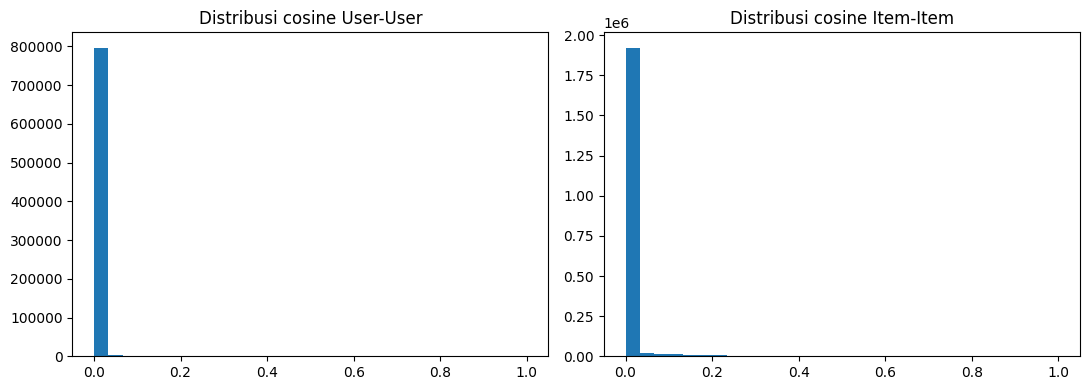

In [8]:
# Proyeksi similarity cosine: User-User dan Item-Item
# Matriks dense hanya dibuat untuk subgraf terbatas di atas.
user_norm = normalize(ui, norm="l2", axis=1)
item_norm = normalize(ui.T, norm="l2", axis=1)
user_sim = (user_norm @ user_norm.T).toarray()
item_sim = (item_norm @ item_norm.T).toarray()
np.fill_diagonal(user_sim,0); np.fill_diagonal(item_sim,0)
print("user_sim:",user_sim.shape,"| item_sim:",item_sim.shape)
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].hist(user_sim[np.triu_indices_from(user_sim,k=1)],bins=30); axes[0].set_title("Distribusi cosine User-User")
axes[1].hist(item_sim[np.triu_indices_from(item_sim,k=1)],bins=30); axes[1].set_title("Distribusi cosine Item-Item")
plt.tight_layout(); plt.show()

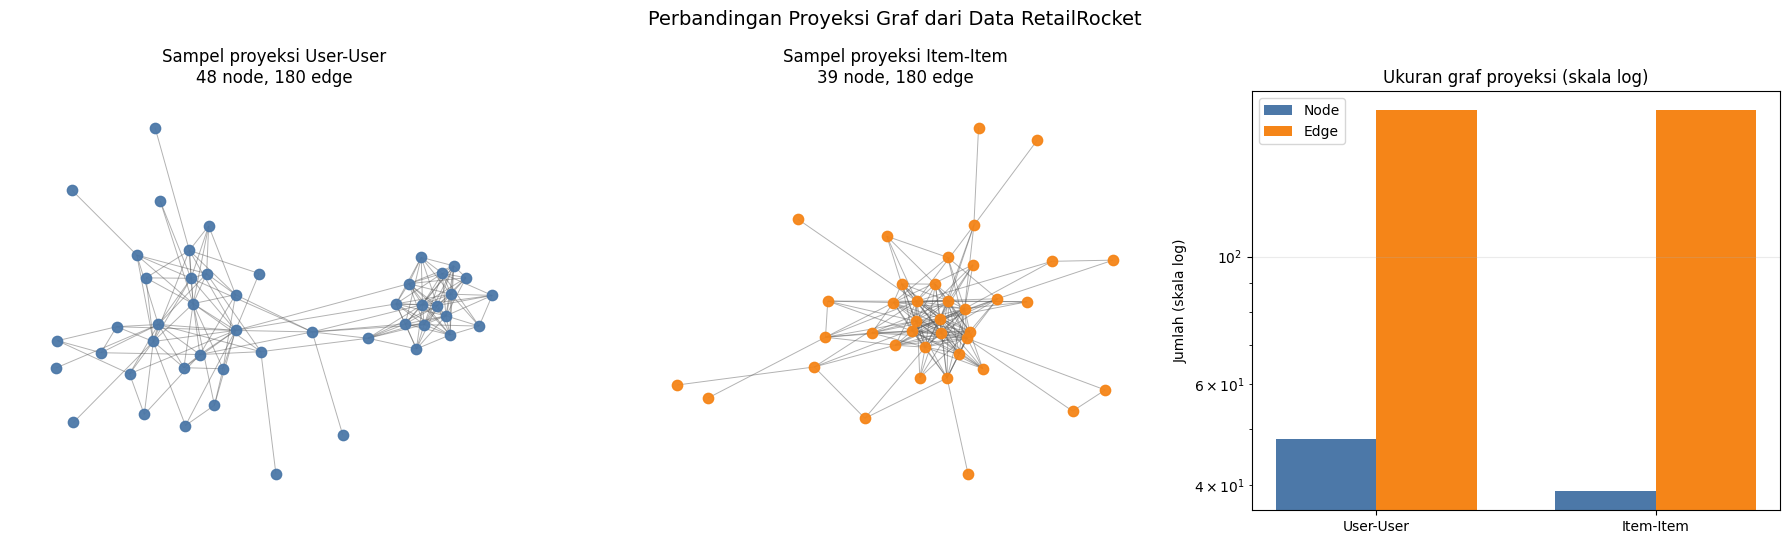

Proyeksi User-User: 48 node, 180 edge
Proyeksi Item-Item: 39 node, 180 edge
Catatan: visualisasi memakai sampel node dan edge dengan similarity tertinggi agar pola garis terlihat jelas.


In [9]:
# Visualisasi seperti contoh: graf User-User, graf Item-Item, dan perbandingan ukuran proyeksi.
# Untuk gambar, ambil 50 node dengan degree tertinggi dan edge similarity tertinggi agar garis terlihat.

def build_display_graph(sim, labels, max_nodes=50, max_edges=180, threshold=0.01):
    labels = np.asarray(labels)
    # Node aktif dipilih berdasarkan jumlah similarity positif (degree potensial).
    strength = (sim >= threshold).sum(axis=1)
    keep_idx = np.argsort(strength)[-min(max_nodes, len(labels)):]
    keep_idx = np.sort(keep_idx)
    sub = sim[np.ix_(keep_idx, keep_idx)]
    sub_labels = labels[keep_idx]
    G = nx.Graph()
    G.add_nodes_from([int(x) for x in sub_labels])
    edges = []
    for i in range(len(sub_labels)):
        for j in range(i + 1, len(sub_labels)):
            score = float(sub[i, j])
            if score >= threshold:
                edges.append((score, int(sub_labels[i]), int(sub_labels[j])))
    edges.sort(key=lambda x: x[0], reverse=True)
    G.add_weighted_edges_from([(a, b, w) for w, a, b in edges[:max_edges]])
    # Hilangkan node terisolasi agar gambar fokus pada node yang benar-benar terhubung.
    G.remove_nodes_from(list(nx.isolates(G)))
    return G

G_user = build_display_graph(user_sim, users, max_nodes=50, max_edges=180, threshold=0.01)
G_item = build_display_graph(item_sim, items, max_nodes=50, max_edges=180, threshold=0.01)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, G, title, node_color in [
    (axes[0], G_user, "Sampel proyeksi User-User", "#4C78A8"),
    (axes[1], G_item, "Sampel proyeksi Item-Item", "#F58518"),
]:
    if G.number_of_nodes() > 0:
        pos = nx.spring_layout(G, seed=SEED, iterations=100, k=1.0 / np.sqrt(max(G.number_of_nodes(), 1)))
        nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#555555", alpha=0.45, width=0.7)
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_color, node_size=55, alpha=0.95)
        ax.set_title(f"{title}\n{G.number_of_nodes()} node, {G.number_of_edges()} edge")
    else:
        ax.text(0.5, 0.5, "Tidak ada edge pada threshold ini", ha="center", va="center")
        ax.set_title(title)
    ax.axis("off")

# Bandingkan ukuran matriks dan jumlah sisi pada graf proyeksi yang divisualisasikan.
labels_bar = ["User-User", "Item-Item"]
node_counts = [G_user.number_of_nodes(), G_item.number_of_nodes()]
edge_counts = [G_user.number_of_edges(), G_item.number_of_edges()]
x = np.arange(2)
width = 0.36
axes[2].bar(x - width/2, np.maximum(node_counts, 1), width, label="Node", color="#4C78A8")
axes[2].bar(x + width/2, np.maximum(edge_counts, 1), width, label="Edge", color="#F58518")
axes[2].set_xticks(x, labels_bar)
axes[2].set_yscale("log")
axes[2].set_title("Ukuran graf proyeksi (skala log)")
axes[2].set_ylabel("Jumlah (skala log)")
axes[2].legend()
axes[2].grid(axis="y", alpha=0.25)

plt.suptitle("Perbandingan Proyeksi Graf dari Data RetailRocket", fontsize=14)
plt.tight_layout()
plt.show()

print("Proyeksi User-User:", G_user.number_of_nodes(), "node,", G_user.number_of_edges(), "edge")
print("Proyeksi Item-Item:", G_item.number_of_nodes(), "node,", G_item.number_of_edges(), "edge")
print("Catatan: visualisasi memakai sampel node dan edge dengan similarity tertinggi agar pola garis terlihat jelas.")


### Diskusi proyeksi mana lebih efektif/efisien?

Bandingkan ukuran: User-User adalah `n_user × n_user`, sedangkan Item-Item adalah `n_item × n_item`. Dalam subgraf terpilih, proyeksi dengan jumlah entitas lebih kecil memiliki matriks similarity yang lebih kecil dan lebih hemat memori/waktu. Namun, hasil aktual bergantung pada jumlah user/item setelah filter; baca nilai `shape` yang dicetak. User-based cocok untuk mencari pengunjung dengan pola interaksi serupa; item-based cocok untuk menemukan produk yang sering beririsan dalam riwayat interaksi. 

In [10]:
user_n, item_n = ui.shape
if user_n < item_n:
    chosen_projection = "User-User"
elif item_n < user_n:
    chosen_projection = "Item-Item"
else:
    chosen_projection = "Sama ukuran"
print(f"Ukuran user projection: {user_n} x {user_n} = {user_n**2:,} elemen")
print(f"Ukuran item projection: {item_n} x {item_n} = {item_n**2:,} elemen")
print("Pilihan berdasarkan ukuran matriks:", chosen_projection)
print("Catatan: ukuran lebih kecil tidak selalu berarti kualitas rekomendasi lebih baik; evaluasi juga kualitas ranking dan biaya komputasi.")

Ukuran user projection: 1270 x 1270 = 1,612,900 elemen
Ukuran item projection: 2013 x 2013 = 4,052,169 elemen
Pilihan berdasarkan ukuran matriks: User-User
Catatan: ukuran lebih kecil tidak selalu berarti kualitas rekomendasi lebih baik; evaluasi juga kualitas ranking dan biaya komputasi.


## 2.1.7 — Similarity dan lima record tertinggi

Pilih satu user acuan secara reproducible. Cari lima user lain dengan cosine similarity tertinggi. Hasil disimpan ke `top5_similarity.csv`. Bila impor ke Neo4j aktif, query Cypher juga dapat menampilkan top-5; property similarity ditambahkan ke relationship `SIMILAR_TO`.

In [11]:
# Acuan dipilih acak dengan seed tetap dari user yang tersedia.
anchor_pos = int(rng.integers(0,len(users)))
anchor_user = int(users[anchor_pos])
order = np.argsort(user_sim[anchor_pos])[::-1]
top_idx = [int(j) for j in order if j != anchor_pos][:5]
top5 = pd.DataFrame({"anchor_user":anchor_user,"similar_user":[int(users[j]) for j in top_idx],"similarity":[float(user_sim[anchor_pos,j]) for j in top_idx]})
top5.to_csv("top5_similarity.csv",index=False)
display(top5)
print("Acuan dipilih dengan np.random.default_rng(42), user:",anchor_user)

,anchor_user,similar_user,similarity
0,137733,1019806,0.457496
1,137733,613876,0.353815
2,137733,1071608,0.348062
3,137733,571349,0.333333
4,137733,1206221,0.333333


Acuan dipilih dengan np.random.default_rng(42), user: 137733


### Cypher: sebelum dan sesudah similarity

Sebelum similarity, graf berisi User–Item dengan relationship interaksi. Sesudah similarity, ditambahkan relationship berarah `SIMILAR_TO` yang memiliki properti `score`. Query top-5 di bawah mengasumsikan relationship tersebut sudah ditulis ke Neo4j.

In [12]:
if IMPORT_TO_NEO4J:
    with GraphDatabase.driver(URI,auth=(USER,PASSWORD)) as driver:
        with driver.session(database=DATABASE) as session:
            # Tulis similarity dua arah agar query dari masing-masing user dapat dilakukan.
            for r in top5.to_dict("records"):
                session.run("""
                MATCH (a:User {userId:$a}), (b:User {userId:$b})
                MERGE (a)-[s:SIMILAR_TO]->(b) SET s.score=$score
                MERGE (b)-[t:SIMILAR_TO]->(a) SET t.score=$score
                """,a=int(r["anchor_user"]),b=int(r["similar_user"]),score=float(r["similarity"]))
            print("Sebelum similarity — relationship interaksi:")
            print([dict(r) for r in session.run("MATCH (u:User)-[r]->(i:Item) RETURN type(r) AS tipe,count(*) AS jumlah ORDER BY tipe")])
            print("Sesudah similarity — top-5 dari user acuan:")
            query_top = "MATCH (a:User {userId:$uid})-[s:SIMILAR_TO]->(b:User) RETURN b.userId AS userId,s.score AS similarity ORDER BY similarity DESC LIMIT 5"
            print([dict(r) for r in session.run(query_top,uid=anchor_user)])

### Query graf sebelum/sesudah (dapat dijalankan di Neo4j Browser)

**Sebelum:** `MATCH (u:User)-[r]->(i:Item) RETURN u,r,i LIMIT 100`

**Sesudah:** `MATCH (u:User)-[s:SIMILAR_TO]->(v:User) RETURN u,s,v ORDER BY s.score DESC LIMIT 50`

Query komposisi: `MATCH ()-[r]->() RETURN type(r), count(*) ORDER BY type(r)`.

## 2.2.1 — Pilih user acak yang reproducible dan rekomendasi KNN (k=5)

Di sini user acuan dipilih dengan seed tetap dari user yang mempunyai setidaknya satu item di P1 dan setidaknya satu item di P2 agar evaluasi dapat dilakukan. KNN mencari 5 user tetangga berdasarkan cosine distance dari matriks user-item. Item yang pernah dilihat/dikunjungi user acuan di P1 dikeluarkan dari kandidat rekomendasi.

In [13]:
# Ground truth testing: semua item yang berinteraksi pada P2.
test_by_user = p2.groupby("visitorid").itemid.apply(lambda x: set(map(int,x)))
train_users_with_test = [int(u) for u in users if int(u) in test_by_user.index]
if not train_users_with_test:
    raise ValueError("Tidak ada user dari matriks training yang muncul di P2. Periksa periode/filter.")
# Pilih user acuan secara acak reproducible dari kandidat yang memiliki ground truth.
rec_rng = np.random.default_rng(SEED)
selected_user = int(rec_rng.choice(train_users_with_test))
selected_pos = users.get_loc(selected_user)
print("Selected user:",selected_user,"| seed:",SEED,"| jumlah item ground truth P2:",len(test_by_user[selected_user]))

# NearestNeighbors cosine distance; fit pada representasi sparse.
knn = NearestNeighbors(metric="cosine",algorithm="brute",n_neighbors=min(6,ui.shape[0]))
knn.fit(ui)
dists, idxs = knn.kneighbors(ui[selected_pos],n_neighbors=min(6,ui.shape[0]))
neighbors = [(int(users[j]),float(1-d)) for j,d in zip(idxs[0],dists[0]) if int(users[j]) != selected_user][:5]
print("5 tetangga (userId, cosine similarity):")
for n in neighbors: print(n)

Selected user: 118580 | seed: 42 | jumlah item ground truth P2: 1
5 tetangga (userId, cosine similarity):
(1128809, 0.9922778767136677)
(293077, 0.9363291775690445)
(888550, 0.40824829046386313)
(673572, 0.2993421700446248)
(856874, 0.2294157338705618)


In [14]:
# Skor item = jumlah similarity tetangga x interaksi tetangga pada item.
item_scores = np.zeros(len(items),dtype=float)
for neighbor_id, sim in neighbors:
    pos = users.get_loc(neighbor_id)
    item_scores += sim * np.asarray(ui[pos].toarray()).ravel()
seen = set(map(int,agg.loc[agg.visitorid==selected_user,"itemid"]))
ranked_positions = np.argsort(item_scores)[::-1]
recommendations=[]
for j in ranked_positions:
    item_id=int(items[j])
    if item_scores[j] <= 0: break
    if item_id not in seen:
        recommendations.append((item_id,float(item_scores[j])))
    if len(recommendations)==5: break
recommendations_df=pd.DataFrame(recommendations,columns=["itemid","score"])
print("Top rekomendasi (maksimal 5):")
display(recommendations_df)
print("Tiga item yang diiklankan untuk k=5:",recommendations_df.itemid.head(3).tolist())

Top rekomendasi (maksimal 5):


,itemid,score
0,171335,2.808988
1,194831,1.796053
2,57245,1.496711
3,352441,1.197369
4,358895,1.197369


Tiga item yang diiklankan untuk k=5: [171335, 194831, 57245]


## 2.2.2 — Evaluasi Hit@5 dan NDCG@5

Ground truth adalah item yang berinteraksi dengan user terpilih pada periode P2. Hit@5 bernilai 1 jika minimal satu rekomendasi top-5 ada pada ground truth, selain itu 0. NDCG@5 menghitung gain item relevan pada posisi ranking; untuk relevansi biner, `DCG = Σ rel_i/log2(i+1)` (indeks posisi dimulai dari 1), dibagi ideal DCG.

In [15]:
ground_truth = set(map(int,test_by_user[selected_user]))
recommended = recommendations_df.itemid.astype(int).tolist()
relevance = [1 if item in ground_truth else 0 for item in recommended[:5]]
hit_at_5 = int(any(relevance))
dcg_at_5 = sum(rel/np.log2(rank+2) for rank,rel in enumerate(relevance))
ideal_relevance = sorted(relevance,reverse=True)
idcg_at_5 = sum(rel/np.log2(rank+2) for rank,rel in enumerate(ideal_relevance))
ndcg_at_5 = float(dcg_at_5/idcg_at_5) if idcg_at_5>0 else 0.0
print("User:",selected_user)
print("Ground truth P2:",len(ground_truth),"item")
print("Rekomendasi:",recommended)
print("Relevance@5:",relevance)
print(f"Hit@5 = {hit_at_5}")
print(f"NDCG@5 = {ndcg_at_5:.4f}")
print("Catatan: jika tidak ada item relevan di daftar rekomendasi, NDCG@5 ditetapkan 0.")

User: 118580
Ground truth P2: 1 item
Rekomendasi: [171335, 194831, 57245, 352441, 358895]
Relevance@5: [0, 0, 0, 0, 0]
Hit@5 = 0
NDCG@5 = 0.0000
Catatan: jika tidak ada item relevan di daftar rekomendasi, NDCG@5 ditetapkan 0.


## Ringkasan hasil untuk ditulis pada laporan

In [16]:
summary = {
    "P1_events": int(len(p1)), "P2_events": int(len(p2)),
    "VSM_shape_users_items": tuple(map(int,ui.shape)), "VSM_nnz": int(ui.nnz),
    "user_projection_shape": (int(ui.shape[0]),int(ui.shape[0])),
    "item_projection_shape": (int(ui.shape[1]),int(ui.shape[1])),
    "similarity_anchor_user": int(anchor_user), "knn_selected_user": int(selected_user),
    "recommendations_top5": recommendations_df.to_dict("records"),
    "Hit@5": int(hit_at_5), "NDCG@5": float(ndcg_at_5),
}
summary

{'P1_events': 304718,
 'P2_events': 145321,
 'VSM_shape_users_items': (1270, 2013),
 'VSM_nnz': 7462,
 'user_projection_shape': (1270, 1270),
 'item_projection_shape': (2013, 2013),
 'similarity_anchor_user': 137733,
 'knn_selected_user': 118580,
 'recommendations_top5': [{'itemid': 171335, 'score': 2.8089875327071336},
  {'itemid': 194831, 'score': 1.796053020267749},
  {'itemid': 57245, 'score': 1.4967108502231241},
  {'itemid': 352441, 'score': 1.1973686801784993},
  {'itemid': 358895, 'score': 1.1973686801784993}],
 'Hit@5': 0,
 'NDCG@5': 0.0}

## Batasan dan interpretasi

1. Timestamp dikonversi ke UTC.
2. P1 dan P2 mengikuti **file yang benar-benar tersedia di data.zip**: P1 = 15–28 Mei 2015 dan P2 = 29 Mei–4 Juni 2015.
3. `events.csv` pada ZIP adalah pointer Git LFS, bukan CSV event penuh, sehingga notebook sengaja menggunakan `events_p1.csv` dan `events_p2.csv`.
4. VSM memakai frekuensi interaksi sebagai bobot; hasil dapat berubah jika hanya event `transaction` yang digunakan.
5. Matriks similarity penuh hanya dihitung pada user/item yang lolos batas `MIN_USER_EVENTS`, `MIN_ITEM_EVENTS`, `MAX_USERS`, dan `MAX_ITEMS` agar laptop tidak kehabisan memori.
6. Hit@5/NDCG@5 dihitung dari item yang muncul pada P2 dan kandidat yang tersedia dalam matriks training.
7. Jika Neo4j digunakan, pastikan DBMS lokal berjalan dan kredensial sesuai. Untuk Neo4j lokal single-instance, `bolt://127.0.0.1:7687` digunakan agar tidak memerlukan routing cluster.


## Visualisasi graf dengan node dan edge

Cell berikut menampilkan graf interaksi bipartit yang benar-benar terdiri dari node `User`, node `Item`, dan garis hubungan `VIEWED`, `ADDED_TO_CART`, serta `BOUGHT`. Sampel dibatasi agar hasilnya terbaca; pembatasan hanya untuk gambar, bukan untuk data impor.


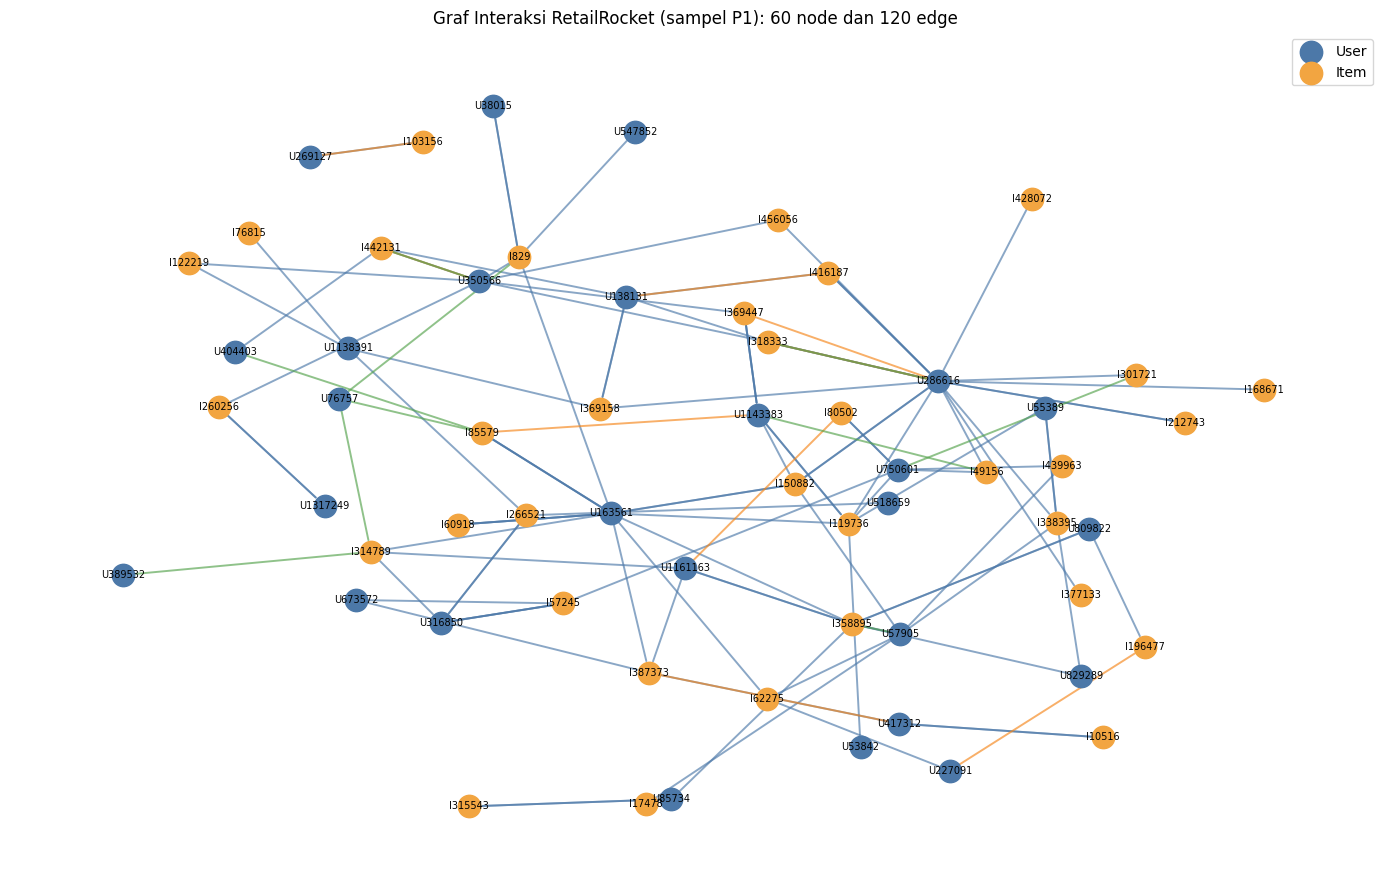

Jumlah node pada gambar: 60
Jumlah edge/garis pada gambar: 120
Node User: 26 | Node Item: 34
Catatan: ini visualisasi sampel agar terbaca; proses impor Neo4j tetap memakai seluruh data P1.


In [17]:
# VISUALISASI GRAF NYATA: NODE DAN EDGE (GARIS)
# Mengambil sampel interaksi P1 supaya gambar tetap terbaca.
# Node biru = User, node oranye = Item; garis menunjukkan jenis interaksi.

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import numpy as np

MAX_VIS_USERS = 35
MAX_VIS_ITEMS = 35
MAX_VIS_EDGES = 120

# Pilih user/item aktif agar graf terlihat jelas dan tidak terlalu padat.
vis_users = p1["visitorid"].value_counts().head(MAX_VIS_USERS).index
vis_items = p1[p1["visitorid"].isin(vis_users)]["itemid"].value_counts().head(MAX_VIS_ITEMS).index
vis_edges = p1[
    p1["visitorid"].isin(vis_users) & p1["itemid"].isin(vis_items)
].copy()

# Batasi jumlah garis untuk visualisasi saja; data asli tidak diubah.
if len(vis_edges) > MAX_VIS_EDGES:
    vis_edges = vis_edges.sample(MAX_VIS_EDGES, random_state=SEED)

G_interaction = nx.MultiGraph()
for uid in vis_edges["visitorid"].unique():
    G_interaction.add_node(f"U{int(uid)}", node_type="User", original_id=int(uid))
for iid in vis_edges["itemid"].unique():
    G_interaction.add_node(f"I{int(iid)}", node_type="Item", original_id=int(iid))

event_style = {
    "view": ("#4C78A8", "VIEWED"),
    "addtocart": ("#F58518", "ADDED_TO_CART"),
    "transaction": ("#54A24B", "BOUGHT"),
}
for _, row in vis_edges.iterrows():
    color, label = event_style.get(str(row["event"]), ("#999999", str(row["event"])))
    G_interaction.add_edge(
        f'U{int(row["visitorid"])}',
        f'I{int(row["itemid"])}',
        event=label,
        color=color
    )

plt.figure(figsize=(14, 9))
pos = nx.spring_layout(G_interaction, seed=SEED, k=0.8, iterations=80)
user_nodes = [n for n, d in G_interaction.nodes(data=True) if d["node_type"] == "User"]
item_nodes = [n for n, d in G_interaction.nodes(data=True) if d["node_type"] == "Item"]

nx.draw_networkx_nodes(
    G_interaction, pos, nodelist=user_nodes,
    node_color="#4C78A8", node_size=260, label="User"
)
nx.draw_networkx_nodes(
    G_interaction, pos, nodelist=item_nodes,
    node_color="#F2A541", node_size=260, label="Item"
)

for event_name, (color, _) in event_style.items():
    edgelist = [
        (u, v) for u, v, k, d in G_interaction.edges(keys=True, data=True)
        if d["event"] == event_style[event_name][1]
    ]
    nx.draw_networkx_edges(
        G_interaction, pos, edgelist=edgelist,
        edge_color=color, width=1.4, alpha=0.65
    )

nx.draw_networkx_labels(G_interaction, pos, font_size=7)
plt.title(
    f"Graf Interaksi RetailRocket (sampel P1): "
    f"{G_interaction.number_of_nodes()} node dan {G_interaction.number_of_edges()} edge"
)
plt.legend(scatterpoints=1)
plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah node pada gambar:", G_interaction.number_of_nodes())
print("Jumlah edge/garis pada gambar:", G_interaction.number_of_edges())
print("Node User:", len(user_nodes), "| Node Item:", len(item_nodes))
print("Catatan: ini visualisasi sampel agar terbaca; proses impor Neo4j tetap memakai seluruh data P1.")
